# 13 — The recommendation: every book financed alike, the distribution of outcomes, a stronger baseline for the language model, and the allocation line by line

**Step 13 of 13 · after notebook 12 — the last notebook.** This notebook closes the pipeline with what notebooks 01–12 built. It scores every decision process under one funding rule with the construction line priced, so that no book is favoured by how it is financed; draws the distribution of held-out outcomes behind every number the portfolio chapters compare; dials the candidates' co-movement from independent to perfect and scores the books in seven worlds; adds the optimizer-first rule as a fifth arm beside the registered four-arm ladder; writes the recommended allocation candidate by candidate; draws the committee's workflow and the control matrix from the code; prices an emissions cap on the book; and records one executive's round through the decision page. Everything here is post-registration and labelled so; no registered line is re-scored.


**Inputs → Outputs**

| | Path | Notes |
|---|---|---|
| in | `data/interim/scenario_state.npz`, `results/candidate_npv.csv` | the engines of notebook 11 (primary and held-out scenarios) |
| in | `results/v8/frontier.csv`, `results/v8/process_comparison.csv`, `results/v8/statuses.csv`, `results/v8/explanations.csv` | books A–D and F as chosen in notebook 11; each candidate's status |
| in | `results/v10/cases_v10.json`, `results/v10/x1_outputs.jsonl` | the registered committee test's cases and the recorded challenger outputs (read, never re-run) |
| out | `results/v2/books_financed.csv`, `books_financed_pairs.csv` | every book under the same funding rule, gross and net of the line's cost; paired intervals |
| out | `results/v2/book_outcomes_heldout.csv`, `book_distributions.csv` | the 2,000 held-out outcomes of each of the five books, and what each distribution says: expected NPV, the worst-5% average loss, the chance of a loss |
| out | `results/v2/dependence_dial.csv`, `books_worlds.csv` | the books as the co-movement is dialled and in seven worlds |
| out | `results/v2/ladder_five_arms.csv`, `ladder_five_rungs.csv` | the registered ladder with the optimizer-first rule as a fifth arm |
| out | `results/v2/worked_example.json` | one executive's round through the decision page (section 7), replayed from the advisor's record |
| out | `results/v2/book_D_members.csv`, `emissions_cap.csv`, `readiness_matrix.csv`, `checks.csv` | the recommended allocation line by line; the book under an emissions cap; the control matrix; this notebook's checks |
| out | `figures/F51_true_economics.*`, `F52_what_can_go_wrong.*`, `F57_book_distributions.*`, `F53_ladder_five_arms.*`, `F54_allocation.*`, `F55_committee_workflow.*`, `F56_readiness_matrix.*` | the report's figures |

In [1]:
import json
import sys
import time
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

sys.path.append(str(Path.cwd().resolve().parent))  # notebooks run from notebooks/; src/ is one level up
from src import challenge as ch, challenge_experiments as cx, challenge_v10 as c10, config, optimizer as opt, paths, plots, robustness as rb, whatif as wi

paths.ensure_dirs()
plots.set_style()
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 40)
pd.set_option("display.max_colwidth", 100)
warnings.filterwarnings("ignore", category=FutureWarning)

NOTEBOOK = "13_executive_corrections"
START = time.time()
R = paths.RESULTS
V2 = R / "v2"
V2.mkdir(exist_ok=True)
LEVEL, LAM, CAP, SEED, N_BOOT = 0.95, 1.0, 0.40, 2020, 1000
SOURCES = [config.SOURCE_BSEE, config.SOURCE_ERCOT]
COHORT = "the forty candidates public on 1 January 2025; 2,000 held-out scenarios"
TECH_COLOR = {"Lease redevelopment": "#D55E00", "Gas CC": config.TECH_COLORS["Gas"], "Solar": config.TECH_COLORS["Solar"], "Wind": config.TECH_COLORS["Wind"], "Storage": config.TECH_COLORS["Battery"]}
BOOK_COLOR = {"A": "#999999", "B": "#CC79A7", "C": "#56B4E9", "D": "#0072B2", "F": "#009E73", "D_L": "#E69F00"}
BOOK_NAME = {"A": "A NPV ranking", "B": "B equal capital", "C": "C deterministic", "D": "D risk-aware", "F": "F lookup forecasts", "D_L": "D re-solved with the line"}

sel = wi.Engine(2000, "primary")
held = wi.Engine(2000, "held-out")
s = ch.Setting(sel, held, "committee")
x_D = np.asarray(s.x_model, int)
lease = np.ones(len(s.ids), bool)
lease[s.power_idx] = False
frontier = pd.read_csv(R / "v8" / "frontier.csv")
books = {row["policy"][0]: s.vector(row["members"].split(";")) for _, row in frontier[frontier["kind"] == "comparator"].iterrows()}
pc = pd.read_csv(R / "v8" / "process_comparison.csv").set_index("process")
books["F"] = s.vector(pc.loc["F D with naive (lookup) forecasts", "members"].split(";"))
assert np.array_equal(books["D"], x_D)
print(f"books: " + ", ".join(f"{k} {int(x.sum())} members" for k, x in books.items()) + f"; budget ${s.budget / 1e9:.2f}B; {time.time() - START:.0f} s")

books: A 15 members, B 18 members, C 17 members, D 13 members, F 20 members; budget $3.82B; 36 s


## 1. Every decision process under the same funding rule

Notebooks 11 and 12 compared the five decision processes on a static basis — every request that reaches its agreement is built, whatever it calls for — and priced a contingent construction line for the risk-aware book alone (notebook 12 §2). The fair question is whether NPV ranking, equal capital, the deterministic optimizer and the lookup book get the same treatment. This section gives every book the same three bases: *static* (unlimited capital, as notebook 11 §7 compared them); *no line* (construction calls beyond the book's own reserve cannot be met, so the requests that reach their agreement forfeit their deposits, `robustness.funding_or_forfeit`); and *its own line* — a facility sized at the 95th percentile of the book's own excess calls, net of the registered 0.5% commitment fee and 8% interest (`robustness.financing_cost`). A fourth basis gives every book the same $2.53B facility book D needs, so that no book is favoured by the size of its line. The funding order within a book is fixed in advance (expected NPV per dollar of capital on the selection scenarios), the rule notebook 12 uses, so no book sees the future. Capital is split into what is spent on the day (lease capital, request deposits), what is reserved for construction (the expected draw), and what is contingent (the facility).

In [2]:
def power_value(x, line, fee, rate, A=None, op_year=None):
    # a book's held-out power value under the funding rule, net of the line's cost; the lease side is unaffected by the line
    A = s.A_h if A is None else A
    op_year = held.op_year if op_year is None else op_year
    reserve = float((s.capex_p * s.p7)[x[s.power_idx] == 1].sum())
    return rb.funding_or_forfeit(A[:, s.power_idx], op_year, s.capex_p, s.carry_p, x[s.power_idx], reserve, line, s.priority, fee=fee, rate=rate)


def totals_of(x, line, fee=0.0, rate=0.0):
    return s.A_h[:, lease] @ x[lease] + power_value(x, line, fee, rate)


def scores_of(t):
    return {"mean": float(t.mean()), "cvar_loss": float(opt.cvar(-t, LEVEL)), "metric": float(t.mean() - LAM * opt.cvar(-t, LEVEL)), "p_loss": float((t < 0).mean())}


LINE_D = float(rb.capital_calls(held.op_year, s.capex_p, x_D[s.power_idx], s.p7)["excess_q95"])  # the facility book D needs (notebook 12)
rows, totals = [], {}
for name, x in books.items():
    xp = x[s.power_idx]
    calls = rb.capital_calls(held.op_year, s.capex_p, xp, s.p7)
    deposits = float((s.carry_p * xp).sum())
    lease_capital = float((s.charge * x)[lease].sum())
    bases = {"static (unlimited capital)": totals_of(x, 1e12), "no line (calls beyond the reserve forfeit)": totals_of(x, 0.0),
             "own line, gross": totals_of(x, calls["excess_q95"]), "own line, net of fee and interest": totals_of(x, calls["excess_q95"], config.LINE_FEE, config.LINE_RATE),
             "common $2.53B line, net of fee and interest": totals_of(x, LINE_D, config.LINE_FEE, config.LINE_RATE)}
    totals[name] = bases
    financing = float(bases["own line, gross"].mean() - bases["own line, net of fee and interest"].mean())
    for basis, t in bases.items():
        rows.append({"book": name, "name": BOOK_NAME[name], "basis": basis, "members": int(x.sum()), "leases": int(x[lease].sum()), "requests": int(xp.sum()),
                     "capital_committed": float(s.charge @ x), "lease_capital": lease_capital, "deposits": deposits, "reserve": calls["reserve"],
                     "facility_own_q95": calls["excess_q95"], "p_calls_over_reserve": calls["p_over"], "financing_cost_mean_own_line": financing, **scores_of(t)})
financed = pd.DataFrame(rows)
financed.to_csv(V2 / "books_financed.csv", index=False)
view = financed.pivot(index="book", columns="basis", values="metric").reindex(list(books)) / 1e9
view = view[["static (unlimited capital)", "no line (calls beyond the reserve forfeit)", "own line, gross", "own line, net of fee and interest", "common $2.53B line, net of fee and interest"]]
lead = {basis: view[basis].idxmax() for basis in view.columns}
print("the book that scores best on the registered metric, by basis: " + "; ".join(f"{b}: {lead[b]}" for b in view.columns))
print(f"book D's facility ${LINE_D / 1e9:.2f}B; {time.time() - START:.0f} s")
view.round(3)

the book that scores best on the registered metric, by basis: static (unlimited capital): D; no line (calls beyond the reserve forfeit): B; own line, gross: D; own line, net of fee and interest: D; common $2.53B line, net of fee and interest: D
book D's facility $2.53B; 37 s


basis,static (unlimited capital),no line (calls beyond the reserve forfeit),"own line, gross","own line, net of fee and interest","common $2.53B line, net of fee and interest"
book,,,,,
A,1.129,0.680,1.016,0.722,0.720
B,1.109,0.867,1.015,0.711,0.788
C,1.212,0.763,1.111,0.820,0.797
D,1.348,0.757,1.268,1.034,1.034
F,1.311,0.771,1.255,0.964,0.975


In [3]:
cap_view = financed[financed["basis"] == "own line, net of fee and interest"].set_index("book")[["members", "leases", "requests", "capital_committed", "lease_capital", "deposits", "reserve", "facility_own_q95", "p_calls_over_reserve", "financing_cost_mean_own_line"]]
(cap_view.assign(**{c: cap_view[c] / 1e9 for c in ("capital_committed", "lease_capital", "deposits", "reserve", "facility_own_q95")}, financing_cost_mean_own_line=cap_view["financing_cost_mean_own_line"] / 1e6)).round(3)

,members,leases,requests,capital_committed,lease_capital,deposits,reserve,facility_own_q95,p_calls_over_reserve,financing_cost_mean_own_line
book,,,,,,,,,,
A,15,4,11,3.812,1.453,0.008,2.351,2.507,0.460,130.531
B,18,8,10,3.421,1.520,0.009,1.892,2.911,0.450,142.688
C,17,8,9,3.811,1.520,0.007,2.284,2.455,0.450,129.146
D,13,5,8,3.778,1.417,0.007,2.354,2.529,0.503,126.243
F,20,8,12,3.748,1.520,0.011,2.218,3.152,0.482,147.179


Paired intervals on the financed basis: the risk-aware book against each conventional book, every book funded within its own line net of the fee and the interest, by resampling held-out scenarios (the rule C33 used, `optimizer.paired_scenario_bootstrap`, applied to the funded totals). A second check re-solves the risk-aware book with book D's $2.53B facility as an explicit constraint — the CVaR of construction calls beyond the reserve must fit within the line (`challenge.liquidity`, the same constraint the challenger's repair uses) — to see whether the recommended book changes when the line is part of the choice rather than priced after it.

In [4]:
def paired(t_a, t_b, n_boot=N_BOOT, seed=SEED):
    # interval of metric(a) - metric(b) by resampling scenarios with replacement, the C33 rule on funded totals
    rng = np.random.default_rng(seed)
    S = len(t_a)
    diffs = np.empty(n_boot)
    for k in range(n_boot):
        idx = rng.integers(0, S, size=S)
        a, b = t_a[idx], t_b[idx]
        diffs[k] = (a.mean() - LAM * opt.cvar(-a, LEVEL)) - (b.mean() - LAM * opt.cvar(-b, LEVEL))
    point = (t_a.mean() - LAM * opt.cvar(-t_a, LEVEL)) - (t_b.mean() - LAM * opt.cvar(-t_b, LEVEL))
    return {"diff": float(point), "low": float(np.quantile(diffs, 0.025)), "high": float(np.quantile(diffs, 0.975))}


# the risk-aware book re-solved with the $2.53B facility as a constraint (post-registration, labelled)
d_l = opt.solve_milp(s.A, s.charge, s.budget, lam=LAM, level=LEVEL, groups=s.tech, group_cap=CAP, calls=s.calls, calls_cap=LINE_D)
x_DL = np.asarray(d_l["x"], int)
books["D_L"] = x_DL
calls_DL = rb.capital_calls(held.op_year, s.capex_p, x_DL[s.power_idx], s.p7)
t_DL = {"own line, net of fee and interest": totals_of(x_DL, calls_DL["excess_q95"], config.LINE_FEE, config.LINE_RATE),
        "common $2.53B line, net of fee and interest": totals_of(x_DL, LINE_D, config.LINE_FEE, config.LINE_RATE), "static (unlimited capital)": totals_of(x_DL, 1e12)}
totals["D_L"] = t_DL
for basis, t in t_DL.items():
    financed = pd.concat([financed, pd.DataFrame([{"book": "D_L", "name": BOOK_NAME["D_L"], "basis": basis, "members": int(x_DL.sum()), "leases": int(x_DL[lease].sum()), "requests": int(x_DL[s.power_idx].sum()),
                                                   "capital_committed": float(s.charge @ x_DL), "facility_own_q95": calls_DL["excess_q95"], "p_calls_over_reserve": calls_DL["p_over"], **scores_of(t)}])], ignore_index=True)
financed.to_csv(V2 / "books_financed.csv", index=False)
pairs = []
for basis in ("static (unlimited capital)", "own line, net of fee and interest", "common $2.53B line, net of fee and interest"):
    for other in ("A", "B", "C", "F"):
        pairs.append({"basis": basis, "book": "D", "against": other, **paired(totals["D"][basis], totals[other][basis])})
    pairs.append({"basis": basis, "book": "D_L", "against": "D", **paired(totals["D_L"][basis], totals["D"][basis])})
pairs = pd.DataFrame(pairs)
pairs.to_csv(V2 / "books_financed_pairs.csv", index=False)
same = int((x_DL == x_D).all())
print(f"D re-solved with the line as a constraint: {int(x_DL.sum())} members, Jaccard to D {opt.jaccard(x_DL, x_D):.2f}, identical to D: {bool(same)}; its own facility ${calls_DL['excess_q95'] / 1e9:.2f}B; {time.time() - START:.0f} s")
(pairs.assign(**{c: pairs[c] / 1e6 for c in ("diff", "low", "high")})).round(0)

D re-solved with the line as a constraint: 9 members, Jaccard to D 0.69, identical to D: False; its own facility $1.31B; 48 s


,basis,book,against,diff,low,high
0,static (unlimited capital),D,A,219.0,18.0,400.0
1,static (unlimited capital),D,B,239.0,47.0,437.0
2,static (unlimited capital),D,C,136.0,-59.0,322.0
3,static (unlimited capital),D,F,37.0,-73.0,154.0
4,static (unlimited capital),D_L,D,-163.0,-229.0,-91.0
5,"own line, net of fee and interest",D,A,312.0,110.0,506.0
6,"own line, net of fee and interest",D,B,323.0,127.0,532.0
7,"own line, net of fee and interest",D,C,213.0,17.0,412.0
8,"own line, net of fee and interest",D,F,70.0,-51.0,201.0
9,"own line, net of fee and interest",D_L,D,-49.0,-127.0,23.0


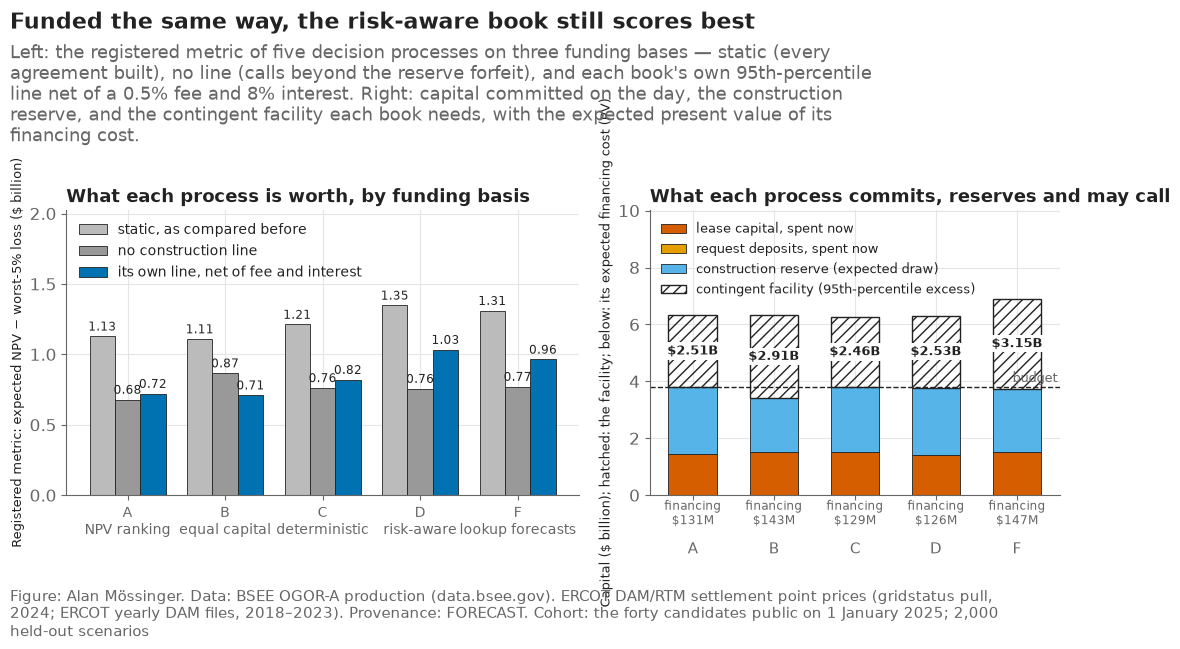

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12.5, 7), gridspec_kw={"width_ratios": [1.2, 1.05]})  # wide enough for both titles and the two-line y-labels (review of 6 November)
order = ["A", "B", "C", "D", "F"]
bases = [("static (unlimited capital)", "static, as compared before", "#BBBBBB"), ("no line (calls beyond the reserve forfeit)", "no construction line", "#999999"),
         ("own line, net of fee and interest", "its own line, net of fee and interest", "#0072B2")]
width = 0.26
for j, (basis, label, color) in enumerate(bases):
    vals = [financed[(financed["book"] == b) & (financed["basis"] == basis)]["metric"].iloc[0] / 1e9 for b in order]
    axes[0].bar(np.arange(len(order)) + (j - 1) * width, vals, width, color=color, label=label, edgecolor=plots.INK, linewidth=0.6)
    for i, v in enumerate(vals):
        axes[0].text(i + (j - 1) * width, v + 0.02, f"{v:.2f}", ha="center", va="bottom", fontsize=8.5, color=plots.INK)
axes[0].set_xticks(np.arange(len(order)), [BOOK_NAME[b].replace(" ", chr(10), 1) for b in order], fontsize=10)
axes[0].set_ylabel("Registered metric, $ billion\n(expected NPV − worst-5% loss)")
axes[0].legend(loc="upper left", fontsize=10, frameon=False)
axes[0].set_ylim(0, max(financed["metric"]) / 1e9 * 1.5)
axes[0].set_title("What each process is worth, by funding basis", fontsize=13)
own = financed[financed["basis"] == "own line, net of fee and interest"].set_index("book").reindex(order)
bottom = np.zeros(len(order))
for col, label, color in (("lease_capital", "lease capital, spent now", "#D55E00"), ("deposits", "request deposits, spent now ($7–11M, too thin to see)", "#E69F00"), ("reserve", "construction reserve (expected draw)", "#56B4E9")):
    v = own[col].to_numpy() / 1e9
    axes[1].bar(np.arange(len(order)), v, 0.6, bottom=bottom, color=color, label=label, edgecolor=plots.INK, linewidth=0.6)
    bottom += v
fac = own["facility_own_q95"].to_numpy() / 1e9
axes[1].bar(np.arange(len(order)), fac, 0.6, bottom=bottom, color="none", edgecolor=plots.INK, hatch="///", linewidth=1.0, label="contingent facility (95th-percentile excess)")
for i, (b, f, c) in enumerate(zip(order, fac, own["financing_cost_mean_own_line"].to_numpy() / 1e6)):
    axes[1].text(i, bottom[i] + f / 2, f"${f:.2f}B", ha="center", va="center", fontsize=9.5, color=plots.INK, fontweight="bold", bbox=dict(facecolor="white", edgecolor="none", pad=1.5))
    axes[1].text(i, -0.12, f"financing\n${c:.0f}M", ha="center", va="top", fontsize=8.5, color=plots.MUTED)
axes[1].axhline(s.budget / 1e9, color=plots.INK, lw=1, ls="--", label=f"budget, ${s.budget / 1e9:.2f}B")  # named in the legend: every bar top sits on the line, so a label beside it would cover one
axes[1].set_xticks(np.arange(len(order)), [b for b in order], fontsize=11)
axes[1].tick_params(axis="x", pad=30)
axes[1].set_ylabel("Capital, $ billion\n(hatched: the facility; below each bar: its financing cost)")
axes[1].set_ylim(0, (bottom + fac).max() * 1.5)
axes[1].legend(loc="upper left", fontsize=9, frameon=False)
axes[1].set_title("What each process commits and may call", fontsize=13)
leader = lead["own line, net of fee and interest"]
title = (f"Funded the same way, the risk-aware book still scores best" if leader == "D" else f"Funded the same way, book {leader} scores best, not the risk-aware one")
plots.finish(fig, title,
             "Left: the registered metric of five decision processes on three funding bases — static (every agreement built), no line (calls beyond the reserve forfeit), and each book's own 95th-percentile line net of a 0.5% fee and 8% interest. Right: capital committed on the day, the construction reserve, and the contingent facility each book needs, with the expected present value of its financing cost.",
             COHORT, lbnl=False, sources=SOURCES, provenance="FORECAST")
plots.save_fig(fig, "F51_true_economics", "The true economics of capital allocation: every decision process on the same funding basis, before and after the construction line is priced, with the capital each commits, reserves and may call.", NOTEBOOK)
plt.show()

**Reading this.** The static comparison of notebook 11 §7 — every request that reaches its agreement is built — priced the construction line for book D alone. On the same funded basis, each book within its own 95th-percentile line net of the 0.5% fee and 8% interest, the risk-aware book scores $1.03B on the registered metric against $0.82B for the deterministic optimizer, $0.72B for NPV ranking, $0.71B for equal capital and $0.96B for the lookup book. Its margin over NPV ranking widens from +$219M on the static basis to +$312M [+$110M, +$506M], and it now beats the deterministic book clear of zero (+$213M [+$17M, +$412M]) where the static comparison did not; against the lookup book the interval still includes zero (+$70M [−$51M, +$201M]). A common $2.53B line gives the same order. Two things the static table hid. First, with no line at all equal capital scores best ($0.87B against $0.76B for D): the recommendation depends on the facility. Second, every process needs one — $2.46B to $3.15B at its own 95th percentile, called beyond the reserve in 45% to 50% of scenarios — and financing costs each of them $126M to $147M in expected present value, so no book is favoured by the line. The capital a committee commits on the day is $3.42B to $3.81B of the $3.82B budget, almost all of it lease capital and construction reserve; the deposits are a few million. The re-solved book, with the $2.53B line as a hard constraint on the CVaR of calls, holds 9 members, needs a $1.31B facility and scores −$49M [−$127M, +$23M] against D on the financed basis: pricing the line after the choice loses nothing, and the recommended book stands.

## 2. What can go wrong: the distribution of outcomes, the co-movement dial and seven worlds

Every number the portfolio chapters compare — expected NPV, the worst-5% average loss, the registered metric, the chance of a loss — is a summary of one distribution: the 2,000 held-out outcomes of a book. Before the dial and the worlds abstract it, this section draws that distribution for each of the five decision processes, the same 2,000 futures read through five different books, and marks on each the 100 worst outcomes whose mean is the worst-5% loss (`optimizer.cvar`, the one definition the optimizer, the tables and the gates share). The picture is what the words *tail* and *risk-aware* mean here: book D does not have fewer bad futures by luck, it holds the members whose bad futures are shallower.

Notebook 12 §4 found that removing the candidates' co-movement cuts book D's worst-5% loss from $0.82B to $0.02B. What does that mean — a real concentration of risk, or a result that hangs on the dependence model? This section dials the co-movement rather than switching it off. For a share ω of the scenario rows each candidate's column keeps its joint alignment and the rest is shuffled: ω = 0 is independence (the ablation), ω = 1 the joint scenarios as scored, and between them the tail grows as the co-movement is restored. A comonotonic bound — every column sorted, so every candidate has its worst scenario on the same day — marks the heaviest tail any dependence structure could give these marginals. Then every book is scored, on the static basis, in seven worlds: the base model, ERCOT prices 25% lower, ERCOT half as volatile, lease capital 30% higher, every plant two years late, completion as the lookup says, and WTI at $45 for five years (the stresses of notebooks 11 and 12 on one table).

In [ ]:
# the 2,000 held-out outcomes of each process, side by side: a book's outcome in a scenario is the sum of its members' NPVs in that scenario
PROCESSES = ("A", "B", "C", "D", "F")
N_TAIL = opt.tail_count(s.A_h.shape[0], LEVEL)  # the 100 worst of 2,000, the count the worst-5% loss averages over
outcomes = pd.DataFrame({name: s.A_h @ books[name] for name in PROCESSES})  # static basis, the matrix the optimizer, the dial and the worlds read
outcomes.to_csv(V2 / "book_outcomes_heldout.csv", index_label="scenario")
drows = []
for name in PROCESSES:
    v = np.sort(outcomes[name].to_numpy())
    drows.append({"book": name, "name": BOOK_NAME[name], "members": int(books[name].sum()), **scores_of(outcomes[name].to_numpy()), "median": float(np.median(v)),
                  "worst": float(v[0]), "tail_cutoff": float(v[N_TAIL - 1]), "tail_mean": float(v[:N_TAIL].mean()), "n_loss": int((v < 0).sum()), "q95": float(np.quantile(v, 0.95)), "best": float(v[-1])})
dist = pd.DataFrame(drows).set_index("book")
assert np.allclose(dist["cvar_loss"], -dist["tail_mean"]), "the worst-5% loss is the mean of the 100 worst outcomes, by definition"
assert np.allclose(dist["mean"], [pc.loc[n, "mean"] for n in ("A NPV ranking", "B equal capital by sector", "C deterministic MILP", "D risk-aware MILP", "F D with naive (lookup) forecasts")], rtol=1e-4), "notebook 11's expected NPVs"
dist.to_csv(V2 / "book_distributions.csv")
print(f"the tail is the {N_TAIL} worst of {len(outcomes):,} held-out outcomes; " + "; ".join(f"{b}: mean ${r['mean'] / 1e9:.2f}B, worst-5% loss ${r['cvar_loss'] / 1e9:.2f}B, loses in {r['p_loss']:.0%}" for b, r in dist.iterrows()) + f"; {time.time() - START:.0f} s")
(dist[["name", "members", "n_loss"]].join((dist[["mean", "median", "tail_cutoff", "cvar_loss", "metric", "worst", "best"]] / 1e9).round(3)).assign(p_loss=dist["p_loss"]))

In [ ]:
fig, grid = plt.subplots(3, 2, figsize=(11, 9), sharex=True, sharey=True)
axes = {name: ax for name, ax in zip(PROCESSES, grid.flat)}
LO = float(np.floor(outcomes.min().min() / 1e9 / 0.5) * 0.5)
HI = 12.0  # outcomes above $12B pooled into the last bin: every book has a few, the deterministic book the most
edges = np.arange(LO, HI + 0.5, 0.5)
for name, ax in axes.items():
    v = np.sort(outcomes[name].to_numpy()) / 1e9
    h_tail, _ = np.histogram(np.clip(v[:N_TAIL], LO, HI - 1e-9), bins=edges)
    h_rest, _ = np.histogram(np.clip(v[N_TAIL:], LO, HI - 1e-9), bins=edges)
    mids = edges[:-1] + 0.25
    ax.bar(mids, h_tail, 0.46, color="#D55E00", label=f"the {N_TAIL} worst futures (5%): their mean\nis the worst-5% average loss")
    ax.bar(mids, h_rest, 0.46, bottom=h_tail, color="#BBBBBB", label=f"the other {len(v) - N_TAIL:,} futures")
    r = dist.loc[name]
    ax.axvline(r["mean"] / 1e9, color="#0072B2", lw=2.2, ls="--", label="expected NPV (the mean of all 2,000)")
    ax.axvline(-r["cvar_loss"] / 1e9, color="#D55E00", lw=2.2, ls="--", label="worst-5% average loss (CVaR95)")
    ax.text(0.98, 0.95, f"{int(r['members'])} members\nexpected NPV \\${r['mean'] / 1e9:.2f}B\nworst-5% average loss \\${r['cvar_loss'] / 1e9:.2f}B\n"
                        f"metric \\${r['metric'] / 1e9:.2f}B · loses money in {r['p_loss']:.0%}\nworst future −\\${-r['worst'] / 1e9:.1f}B",  # the dollar signs escaped: two in one string read as mathtext
            transform=ax.transAxes, ha="right", va="top", fontsize=10, color=plots.INK, linespacing=1.35)
    ax.set_title(BOOK_NAME[name] + (" — the recommended book" if name == "D" else ""), fontsize=12.5, color=BOOK_COLOR[name] if name == "D" else plots.INK)
    ax.tick_params(labelsize=10)
ymax = max(np.histogram(np.clip(outcomes[n].to_numpy() / 1e9, LO, HI - 1e-9), bins=edges)[0].max() for n in PROCESSES) * 1.75  # headroom for the five-line summary
for ax in grid.flat:
    ax.set_ylim(0, ymax)
for ax in grid[:, 0]:
    ax.set_ylabel("futures", fontsize=11)
ticks = np.arange(np.ceil(LO), HI + 1, 2.0)
grid[-1, 0].set_xticks(ticks, [f"{t:.0f}" if t < HI else f"{t:.0f}+" for t in ticks], fontsize=10)
grid[-1, 0].set_xlabel("Twenty-year NPV of the book, \\$ billion (bins of \\$0.5B)", fontsize=11)
axes["D"].tick_params(labelbottom=True)  # the panel above the legend keeps its own axis labels
spare = grid[-1, -1]  # the sixth panel holds the legend
spare.set_axis_off()
handles, labels = axes["D"].get_legend_handles_labels()
spare.legend(handles, labels, loc="center", fontsize=10.5, frameon=False, labelspacing=1.0)
plots.finish(fig, f"The highest expected return is not the best investment: the risk-aware book keeps the thinnest tail",
             "Each panel is the same 2,000 held-out futures read through a different book: a book's outcome in a future is the sum of its members' NPVs in that future. The worst 100 are shaded; the dashed lines mark the expected NPV (the mean of all 2,000) and the worst-5% average loss (the mean of the 100 worst), the two numbers the registered metric subtracts. Static basis, committee grid.",
             COHORT, lbnl=False, sources=SOURCES, provenance="FORECAST")
plots.save_fig(fig, "F57_book_distributions", "The 2,000 held-out twenty-year outcomes of each of the five decision processes, the 100 worst shaded: their mean is the worst-5% average loss, and the dashed lines mark it and the expected NPV.", NOTEBOOK)
plt.show()

**Reading this.** The five panels are one set of 2,000 futures, not five: a book's outcome in a future is the sum of its members' NPVs in that future, so the histograms differ only because the members do, and the books move together across futures (the correlation of book D's outcomes with the deterministic book's is 0.83, with NPV ranking's 0.82). Every book earns most of its futures between $0B and $4B; the differences are in the two ends. On the left, the 100 worst futures — the shaded bars, whose mean is the worst-5% average loss — reach −$4.0B for NPV ranking, −$3.9B for the deterministic book and −$3.6B for equal capital, and average a loss of $1.55B, $1.52B and $1.33B; the risk-aware book's worst future is −$2.0B and its 100 worst average $0.82B, the thinnest tail of the five, and it loses money in 171 futures (9%) against 227 to 243 (11% to 12%) for the conventional books. On the right, the deterministic book and NPV ranking have the longest upside — 35 futures each above $12B, pooled in the last bin, against 3 for book D — which is where their higher expected NPV comes from ($2.73B and $2.68B against $2.17B). That is the trade the tail weight prices: against the deterministic book, book D gives up $0.56B of expected value and $0.70B of worst-5% loss, so on the registered metric it leads by $136M on the static basis [−$63M, +$323M], by $219M over NPV ranking (C33, [+$13M, +$401M]) and $239M over equal capital, and by $37M over the lookup book [−$76M, +$151M], whose distribution sits between D's and the conventional books' (tail $1.09B, 10% of futures losing). Future by future the risk-aware book is better than the deterministic book in only 49% of them; in the deterministic book's 100 worst it is better by $1.06B on average. The medians tell the same story as the means (D $1.82B, C $2.06B): the risk-aware book is not the one that does best in a typical future, it is the one that does least badly in a bad one. Static basis, so that the panels read with the process comparison of notebook 11 §7 and section 1's static column; the financed ranking of section 1 is the same.

In [6]:
rng = np.random.default_rng(SEED)
S_, n_ = s.A_h.shape
dial_rows = []
OMEGAS = (0.0, 0.25, 0.5, 0.75, 1.0)
matrices = {}
for omega in OMEGAS:
    A_w = s.A_h.copy()
    keep = rng.random(S_) < omega  # the rows that keep their joint alignment
    free = np.where(~keep)[0]
    for j in range(n_):
        A_w[free, j] = A_w[rng.permutation(free), j]  # the rest shuffled within themselves: every candidate's own distribution is kept
    matrices[f"omega {omega:g}"] = A_w
A_co = np.sort(s.A_h, axis=0)  # comonotonic: every candidate's k-th worst value on the same row
matrices["comonotonic bound"] = A_co
for label, A_w in matrices.items():
    for name in ("A", "B", "C", "D", "F"):
        t = A_w @ books[name]
        dial_rows.append({"dependence": label, "omega": float(label.split()[1]) if label.startswith("omega") else np.nan, "book": name, **scores_of(t)})
dial = pd.DataFrame(dial_rows)
dial.to_csv(V2 / "dependence_dial.csv", index=False)
dD = dial[dial["book"] == "D"].set_index("dependence")
print("book D's worst-5% loss as the co-movement is dialled: " + "; ".join(f"{k} ${v / 1e9:.2f}B" for k, v in dD["cvar_loss"].items()) + f"; {time.time() - START:.0f} s")
(dial.pivot(index="dependence", columns="book", values="cvar_loss").reindex(list(matrices)) / 1e9).round(3)

book D's worst-5% loss as the co-movement is dialled: omega 0 $-0.03B; omega 0.25 $0.20B; omega 0.5 $0.53B; omega 0.75 $0.69B; omega 1 $0.82B; comonotonic bound $2.19B; 50 s


book,A,B,C,D,F
dependence,,,,,
omega 0,0.467,0.282,0.213,-0.027,-0.038
omega 0.25,0.838,0.682,0.725,0.202,0.327
omega 0.5,1.164,0.949,1.054,0.534,0.706
omega 0.75,1.424,1.254,1.384,0.690,0.922
omega 1,1.550,1.329,1.518,0.822,1.089
comonotonic bound,3.658,3.254,3.425,2.186,2.754


In [7]:
world_set = cx.worlds(s)  # base, ERCOT -25%, ERCOT half as volatile, lease capital +30%, completion as the lookup says
world_set["every plant two years late"] = (ch.held_matrix(s, wi.WhatIf(grid="committee", delay_years=2)), held.op_year)
world_set["WTI at $45 for five years"] = (ch.held_matrix(s, wi.WhatIf(grid="committee", wti_level=45.0)), held.op_year)
WORLD_ORDER = ["base model", "ERCOT prices 25% lower", "ERCOT half as volatile", "lease capital 30% higher", "every plant two years late", "completion as the lookup says", "WTI at $45 for five years"]
wrows = []
for world in WORLD_ORDER:
    A_w, _ = world_set[world]
    for name in ("A", "B", "C", "D", "F"):
        wrows.append({"world": world, "book": name, **scores_of(A_w @ books[name])})
worlds_tab = pd.DataFrame(wrows)
worlds_tab.to_csv(V2 / "books_worlds.csv", index=False)
best_by_world = worlds_tab.loc[worlds_tab.groupby("world")["metric"].idxmax()].set_index("world")["book"].reindex(WORLD_ORDER)
print("the book that scores best on the registered metric, by world: " + "; ".join(f"{w}: {b}" for w, b in best_by_world.items()) + f"; {time.time() - START:.0f} s")
(worlds_tab.pivot(index="world", columns="book", values="metric").reindex(WORLD_ORDER) / 1e9).round(3)

the book that scores best on the registered metric, by world: base model: D; ERCOT prices 25% lower: D; ERCOT half as volatile: D; lease capital 30% higher: D; every plant two years late: D; completion as the lookup says: D; WTI at $45 for five years: D; 140 s


book,A,B,C,D,F
world,,,,,
base model,1.129,1.109,1.212,1.348,1.311
ERCOT prices 25% lower,-0.840,-0.425,-0.749,0.544,0.019
ERCOT half as volatile,0.314,0.548,0.403,0.896,0.715
lease capital 30% higher,0.138,0.075,0.187,0.360,0.267
every plant two years late,0.966,0.959,1.033,1.200,1.153
completion as the lookup says,2.330,2.412,2.674,2.741,2.682
WTI at $45 for five years,-0.061,-0.142,-0.026,0.223,0.103


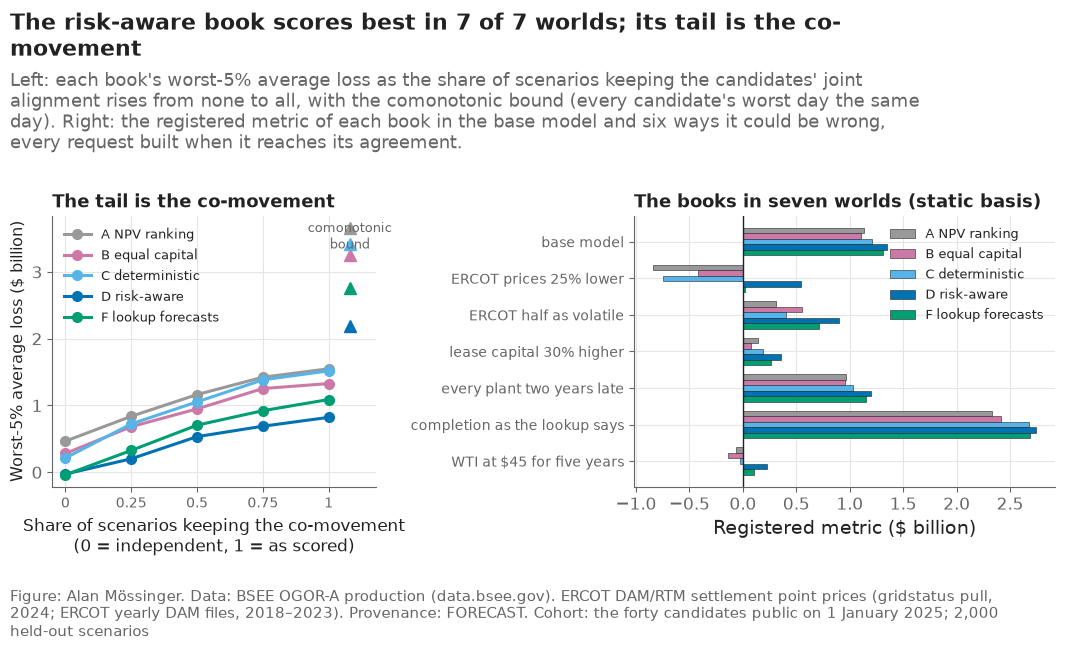

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(11, 6.5), gridspec_kw={"width_ratios": [1, 1.3]})
for name in ("A", "B", "C", "D", "F"):
    d = dial[(dial["book"] == name) & dial["omega"].notna()].sort_values("omega")
    axes[0].plot(d["omega"], d["cvar_loss"] / 1e9, marker="o", lw=2.2, ms=7, color=BOOK_COLOR[name], label=BOOK_NAME[name])
    co = dial[(dial["book"] == name) & (dial["dependence"] == "comonotonic bound")]["cvar_loss"].iloc[0] / 1e9
    axes[0].plot([1.08], [co], marker="^", ms=9, color=BOOK_COLOR[name], ls="none")
axes[0].text(1.08, axes[0].get_ylim()[1] * 0.98, "comonotonic\nbound", ha="center", va="top", fontsize=9, color=plots.MUTED)
axes[0].set_xticks(list(OMEGAS), ["0", "0.25", "0.5", "0.75", "1"], fontsize=10)
axes[0].set_xlim(-0.05, 1.18)
axes[0].set_xlabel("Share of scenarios keeping the co-movement\n(0 = independent, 1 = as scored)", fontsize=12)
axes[0].set_ylabel("Worst-5% average loss ($ billion)")
axes[0].legend(fontsize=9.5, frameon=False, loc="upper left")
axes[0].set_title("The tail is the co-movement", fontsize=13)
wv = worlds_tab.pivot(index="world", columns="book", values="metric").reindex(WORLD_ORDER) / 1e9
y = np.arange(len(WORLD_ORDER))
h = 0.15
for j, name in enumerate(("A", "B", "C", "D", "F")):
    axes[1].barh(y + (j - 2) * h, wv[name], h, color=BOOK_COLOR[name], label=BOOK_NAME[name], edgecolor=plots.INK, linewidth=0.4)
axes[1].axvline(0, color=plots.INK, lw=1)
axes[1].set_yticks(y, WORLD_ORDER, fontsize=10)
axes[1].invert_yaxis()
axes[1].set_xlabel("Registered metric ($ billion)")
axes[1].legend(fontsize=9, frameon=False, loc="upper right")
axes[1].set_title("The books in seven worlds (static basis)", fontsize=13)
n_best_D = int((best_by_world == "D").sum())
plots.finish(fig, f"The risk-aware book scores best in {n_best_D} of 7 worlds; its tail is the co-movement",
             "Left: each book's worst-5% average loss as the share of scenarios keeping the candidates' joint alignment rises from none to all, with the comonotonic bound (every candidate's worst day the same day). Right: the registered metric of each book in the base model and six ways it could be wrong, every request built when it reaches its agreement.",
             COHORT, lbnl=False, sources=SOURCES, provenance="FORECAST")
plots.save_fig(fig, "F52_what_can_go_wrong", "What can go wrong: the books' tails as the candidates' co-movement is dialled from independent to perfect, and their value in seven modelled worlds.", NOTEBOOK)
plt.show()

**Reading this.** The tail grows with the co-movement and with nothing else: book D's worst-5% loss is a profit at ω = 0 (−$0.03B), $0.20B at a quarter, $0.53B at half, $0.69B at three quarters and $0.82B as scored, and the comonotonic bound — every candidate's worst day the same day — is $2.19B, against $3.66B for NPV ranking and $3.43B for the deterministic book. Book D keeps the smallest tail at every setting; it loses the metric lead only when more than half the co-movement is removed (at ω = 0.5 the deterministic book scores $1.68B against $1.64B, at ω = 0 $2.52B against $2.20B). So the risk is a real concentration — five leases on one oil path, eight requests on one ERCOT path — and not an artefact of the dependence model; it would be one only if the true co-movement were much weaker than 2018–2024's, and the first year after the decision gave no sign of that. In the seven worlds the risk-aware book scores best on the registered metric in all 7, and it is the only book whose metric stays positive when ERCOT prices are 25% lower ($0.54B against −$0.84B for NPV ranking and −$0.75B for the deterministic book) or oil sits at $45 for five years ($0.22B against −$0.06B and −$0.03B). Under the lookup's completion rates every book gains and D still leads ($2.74B against $2.67B). The static basis is used here so that the worlds compare with notebooks 11 and 12; the financed ranking of section 1 is the same.

## 3. A stronger baseline for the language model: the optimizer-first rule as a fifth arm

The registered ladder (notebook 12, section 6) has four arms: the committee's proposal, the tools alone (the checklist, which guides to the repair, the smallest change that keeps the rules), the tools with the language model, and the optimizer's book under the committee's true rules. The first challenger test (notebook 11 §11) had shown that a fixed rule which takes the optimizer's book first, whenever it keeps the rules and either fixes a breach or beats the proposal clear of zero, removed most of the model's edge over the checklist (+$1M). The final test needs the same stronger baseline. This section adds it as a fifth arm on the registered test's cases and their recorded outputs — nothing is re-run, no model is called — scored as the ladder is: the committee's own objective in five worlds, funded within its stated line net of the fee and the interest, paired per case with case-bootstrap intervals over all 48 cases. The rule reads no words: it acts on the checklist's flags and the computed alternatives alone. Post-registration and reported beside C34, which stays scored as registered.

In [9]:
s.fee, s.rate = config.LINE_FEE, config.LINE_RATE
cases10 = c10.with_members(s, c10.cases_v10())
records = {json.loads(line)["id"]: json.loads(line) for line in (R / "v10" / "x1_outputs.jsonl").read_text(encoding="utf-8").splitlines() if line.strip()}
assert set(records) == {c["id"] for c in cases10}, "the recorded outputs and the registered cases differ"
ARMS5 = ("proposal", "tools", "optimizer_first", "tools_llm", "optimizer")
world5 = {k: world_set[k] for k in ("base model", "ERCOT prices 25% lower", "ERCOT half as volatile", "lease capital 30% higher", "completion as the lookup says")}
lrows = []
for c in cases10:
    r = records[c["id"]]
    prefs = ch.Preferences(**c["prefs"])  # the committee's true rules
    fb = c10.final_books_v10(s, c, r)
    fb["optimizer_first"] = np.asarray(cx.optimizer_first(s, c, r), int)
    for wname, (A_w, oy) in world5.items():
        for arm in ARMS5:
            t = cx.world_totals(s, fb[arm], prefs, A_w, oy)
            lrows.append({"id": c["id"], "flaw": c["flaw"], "world": wname, "arm": arm, "changed": bool(np.any(fb[arm] != fb["proposal"])), **ch.scores_of(t, prefs.lam)})
ladder5 = pd.DataFrame(lrows)
ladder5.to_csv(V2 / "ladder_five_arms.csv", index=False)
per = ladder5.pivot_table(index=["id", "world"], columns="arm", values="metric").groupby(level="id").mean()
rung_defs = {"tools_minus_proposal": ("tools", "proposal"), "optimizer_first_minus_tools": ("optimizer_first", "tools"), "tools_llm_minus_optimizer_first": ("tools_llm", "optimizer_first"),
             "tools_llm_minus_tools": ("tools_llm", "tools"), "optimizer_minus_tools_llm": ("optimizer", "tools_llm"), "optimizer_minus_optimizer_first": ("optimizer", "optimizer_first")}
rungs5 = pd.DataFrame([{"rung": k, **cx.case_bootstrap(per[a] - per[b])} for k, (a, b) in rung_defs.items()])
rungs5.to_csv(V2 / "ladder_five_rungs.csv", index=False)
reg = pd.read_csv(R / "v10" / "ladder_rungs.csv").set_index("rung")
r5 = rungs5.set_index("rung")
assert np.isclose(r5.loc["tools_llm_minus_tools", "mean"], reg.loc["tools_llm_minus_tools", "mean"]), "the registered rung must reproduce"
arm_means = ladder5.groupby("arm")["metric"].mean().reindex(list(ARMS5))
print("mean objective per arm ($M): " + "; ".join(f"{a} {v / 1e6:,.0f}" for a, v in arm_means.items()))
print(f"the language model against the optimizer-first rule: {r5.loc['tools_llm_minus_optimizer_first', 'mean'] / 1e6:+.0f}M [{r5.loc['tools_llm_minus_optimizer_first', 'low'] / 1e6:+.0f}, {r5.loc['tools_llm_minus_optimizer_first', 'high'] / 1e6:+.0f}]; "
      f"the rule against the checklist {r5.loc['optimizer_first_minus_tools', 'mean'] / 1e6:+.0f}M [{r5.loc['optimizer_first_minus_tools', 'low'] / 1e6:+.0f}, {r5.loc['optimizer_first_minus_tools', 'high'] / 1e6:+.0f}]; "
      f"registered C34 reproduced {r5.loc['tools_llm_minus_tools', 'mean'] / 1e6:+.0f}M; {time.time() - START:.0f} s")
(rungs5.set_index("rung")[["mean", "low", "high"]] / 1e6).round(0)

mean objective per arm ($M): proposal 863; tools 939; optimizer_first 995; tools_llm 981; optimizer 1,116
the language model against the optimizer-first rule: -14M [-36, +2]; the rule against the checklist +56M [+19, +100]; registered C34 reproduced +43M; 546 s


,mean,low,high
rung,,,
tools_minus_proposal,76.0,13.0,140.0
optimizer_first_minus_tools,56.0,19.0,100.0
tools_llm_minus_optimizer_first,-14.0,-36.0,2.0
tools_llm_minus_tools,43.0,9.0,86.0
optimizer_minus_tools_llm,134.0,72.0,211.0
optimizer_minus_optimizer_first,121.0,59.0,195.0


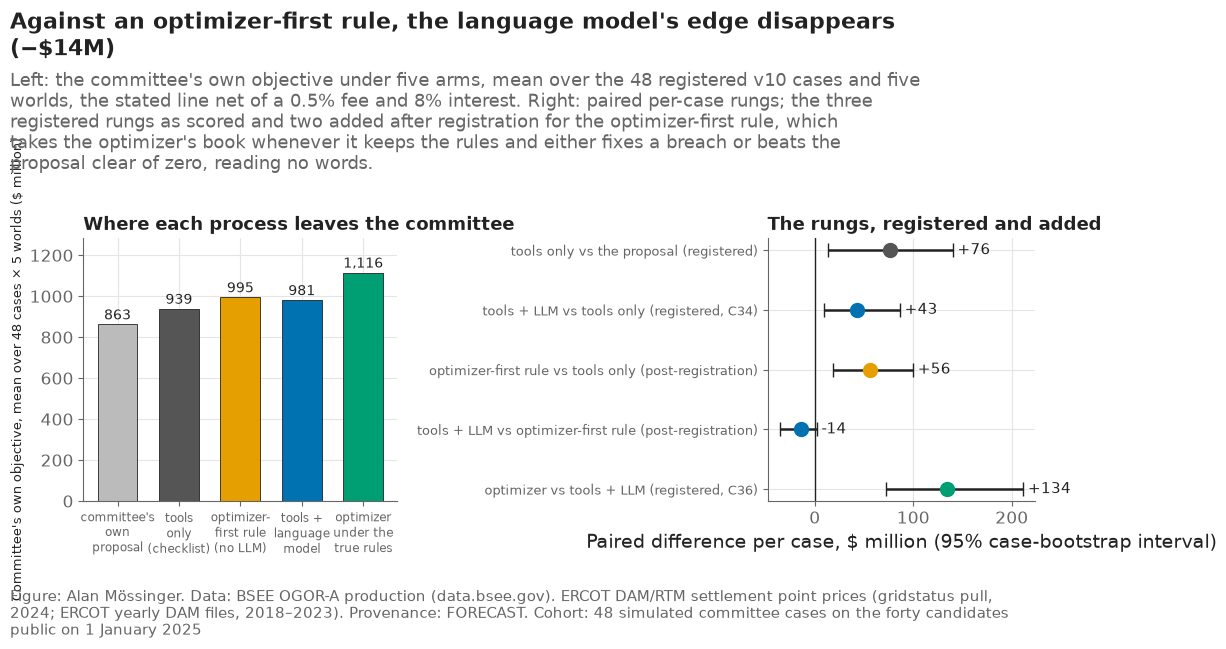

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(13, 7.2), gridspec_kw={"width_ratios": [1.2, 1.0]})  # wide enough for the wrapped rung labels (review of 6 November)
arm_label = {"proposal": "committee's\nown\nproposal", "tools": "tools\nonly\n(checklist)", "optimizer_first": "optimizer-\nfirst rule\n(no LLM)", "tools_llm": "tools +\nlanguage\nmodel", "optimizer": "optimizer\nunder the\ntrue rules"}
arm_color = {"proposal": "#BBBBBB", "tools": "#555555", "optimizer_first": "#E69F00", "tools_llm": "#0072B2", "optimizer": "#009E73"}
vals = arm_means / 1e6
axes[0].bar(np.arange(len(ARMS5)), vals, 0.65, color=[arm_color[a] for a in ARMS5], edgecolor=plots.INK, linewidth=0.6)
for i, v in enumerate(vals):
    axes[0].text(i, v + 8, f"{v:,.0f}", ha="center", va="bottom", fontsize=10, color=plots.INK)
axes[0].set_xticks(np.arange(len(ARMS5)), [arm_label[a] for a in ARMS5], fontsize=8.8)
axes[0].set_ylabel("Committee's own objective, $ million\n(mean over 48 cases × 5 worlds)")
axes[0].set_ylim(0, vals.max() * 1.15)
axes[0].set_title("Where each process leaves the committee", fontsize=13)
order = [("tools_minus_proposal", "tools only vs the proposal\n(registered)", "#555555"), ("tools_llm_minus_tools", "tools + LLM vs tools only\n(registered, C34)", "#0072B2"),
         ("optimizer_first_minus_tools", "optimizer-first rule vs tools only\n(post-registration)", "#E69F00"), ("tools_llm_minus_optimizer_first", "tools + LLM vs optimizer-first rule\n(post-registration)", "#0072B2"),
         ("optimizer_minus_tools_llm", "optimizer vs tools + LLM\n(registered, C36)", "#009E73")]
for i, (key, label, color) in enumerate(order):
    r = r5.loc[key]
    axes[1].errorbar(r["mean"] / 1e6, i, xerr=[[(r["mean"] - r["low"]) / 1e6], [(r["high"] - r["mean"]) / 1e6]], fmt="o", color=color, ecolor=plots.INK, capsize=5, ms=10, lw=1.8)
    axes[1].text(r["high"] / 1e6 + 5, i, f"{r['mean'] / 1e6:+.0f}", va="center", fontsize=11, color=plots.INK)
axes[1].axvline(0, color=plots.INK, lw=1)
axes[1].set_yticks(np.arange(len(order)), [l for _, l, _ in order], fontsize=9.5)
axes[1].invert_yaxis()
axes[1].set_xlim(right=r5.loc[[k for k, _, _ in order], "high"].max() / 1e6 + 45)  # room for the value labels inside the axes
axes[1].set_xlabel("Paired difference per case, $ million\n(95% case-bootstrap interval)")
axes[1].set_title("The rungs, registered and added", fontsize=13)
edge = r5.loc["tools_llm_minus_optimizer_first"]
verdict = "survives" if edge["low"] > 0 else ("disappears" if edge["high"] > 0 else "reverses")
plots.finish(fig, f"Against an optimizer-first rule, the language model's edge {verdict} ({'+' if edge['mean'] >= 0 else '−'}\\${abs(edge['mean']) / 1e6:.0f}M)",
             "Left: the committee's own objective under five arms, mean over the 48 registered v10 cases and five worlds, the stated line net of a 0.5% fee and 8% interest. Right: paired per-case rungs; the three registered rungs as scored and two added after registration for the optimizer-first rule, which takes the optimizer's book whenever it keeps the rules and either fixes a breach or beats the proposal clear of zero, reading no words.",
             "48 simulated committee cases on the forty candidates public on 1 January 2025", lbnl=False, sources=SOURCES, provenance="FORECAST")
plots.save_fig(fig, "F53_ladder_five_arms", "The attribution ladder with a stronger baseline: the optimizer-first rule as a fifth arm beside the registered four, paired per case.", NOTEBOOK)
plt.show()

**Reading this.** The fixed rule that takes the optimizer's book first — whenever it keeps the committee's rules and either fixes a breach or beats the proposal clear of zero — leaves the committee at $995M per case, the challenger at $981M: against this rule the language model's edge is −$14M [−$36M, +$2M], an interval that includes zero and sits almost entirely below it. The rule itself beats the checklist by +$56M [+$19M, +$100M], more than the language model's registered +$43M, and both change the book in the same 23 cases; the model does better in two cases and worse in six, the largest a case in which it guided to the repair where the rule took the optimizer's book. The registered rungs reproduce exactly (+$76M, +$43M, +$134M), so C34 stands as scored: adding the model to the checklist helps. What this arm shows is that the help is not in the choice of book — a rule that reads no words chooses at least as well — and the optimizer under the committee's true rules is a further +$121M [+$59M, +$195M] above the rule. The model's distinct contribution is the one the tools cannot make: naming a sunk cost, a double standard or an unsupported claim (C41, 12 of 12) without over-challenging (C40, 0 of 12), and asking the committee the question its statement leaves open. The first registered test read the same thing (+$1M against the optimizer-first rule); the final test confirms it on author-written cases.

## 4. The recommended allocation, candidate by candidate

The report needs the risk-aware book as a table: what each member costs the budget on the day, what it is expected to earn, how often it loses, what the book gives up by removing it, and its status (notebook 11's gates: invest now, invest in stages, defer pending information, monitor, reject). The members' numbers are notebook 11's (`results/v8/statuses.csv`, `explanations.csv`); this section joins them and draws them.

In [11]:
statuses = pd.read_csv(R / "v8" / "statuses.csv")
expl = pd.read_csv(R / "v8" / "explanations.csv")[["project_id", "objective_cost_$M", "expected_npv_change_$M", "cvar_change_$M", "held_q05_$M", "held_q95_$M"]]
cand = sel.candidates[["project_id", "technology", "mw", "agreement_known"]].copy() if "agreement_known" in sel.candidates else sel.candidates[["project_id", "technology", "mw"]].copy()
members = statuses.merge(expl, on="project_id", how="left").merge(cand.drop(columns=["technology"], errors="ignore"), on="project_id", how="left", suffixes=("", "_cand"))
members["label"] = [f"{p.split('|')[-1]} {t}" + (f" {m:.0f} MW" if pd.notna(m) and t != "Lease redevelopment" else "") for p, t, m in zip(members["project_id"], members["technology"], members["mw"])]
members = members.sort_values(["in_book", "charge_$M"], ascending=[False, False]).reset_index(drop=True)
members.to_csv(V2 / "book_D_members.csv", index=False)
in_book = members[members["in_book"]]
print(f"book D: {len(in_book)} members, ${in_book['charge_$M'].sum() / 1e3:.2f}B committed, expected NPV ${in_book['expected_npv_$M'].sum() / 1e3:.2f}B (sum of members); "
      f"statuses: {members['status'].value_counts().to_dict()}; {time.time() - START:.0f} s")
in_book[["label", "status", "charge_$M", "expected_npv_$M", "p_negative", "objective_cost_$M", "held_q05_$M", "held_q95_$M"]].round(1)

book D: 13 members, $3.78B committed, expected NPV $2.22B (sum of members); statuses: {'monitor': 14, 'defer pending information': 12, 'invest now': 8, 'invest in stages': 5, 'reject': 1}; 548 s


,label,status,charge_$M,expected_npv_$M,p_negative,objective_cost_$M,held_q05_$M,held_q95_$M
0,24INR0075 Solar 1004 MW,invest now,758.5,85.7,0.6,19.8,-194.1,393.7
1,23INR0029 Gas CC 697 MW,invest now,620.0,437.0,0.6,144.6,-570.3,2535.1
2,26INR0113 Wind 836 MW,invest now,535.3,410.7,0.6,539.1,-0.7,1431.0
3,G26253 Lease redevelopment,invest now,447.7,293.4,0.2,3.2,-162.4,911.1
4,G09982 Lease redevelopment,invest now,395.4,306.0,0.1,64.2,-100.5,906.7
5,G16942 Lease redevelopment,invest now,220.2,169.3,0.1,6.3,-59.5,502.3
6,G17015 Lease redevelopment,invest now,219.3,168.4,0.1,8.0,-57.2,486.7
7,26INR0046 Solar 1029 MW,invest in stages,176.3,13.2,0.9,4.0,-0.9,171.5
8,G25814 Lease redevelopment,invest now,134.7,104.7,0.1,12.3,-34.0,304.6
9,28INR0033 Wind 1200 MW,invest in stages,86.7,70.7,1.0,72.0,-1.0,-1.0


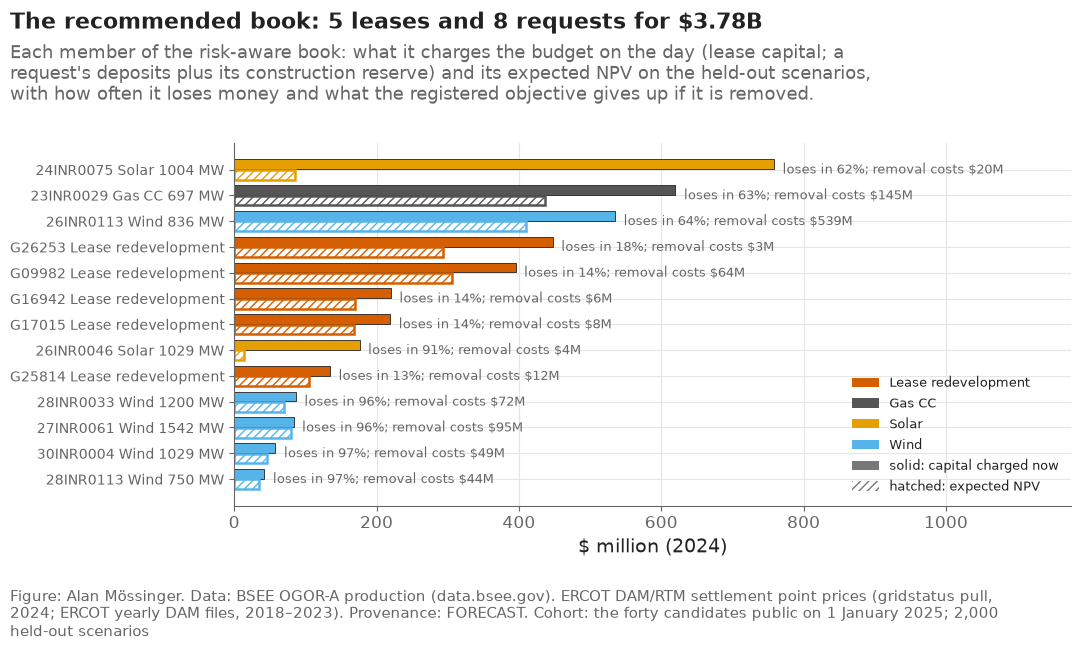

In [12]:
fig, ax = plt.subplots(figsize=(11, 6.5))
m = in_book.sort_values("charge_$M", ascending=True)
y = np.arange(len(m))
ax.barh(y + 0.2, m["charge_$M"], 0.38, color=[TECH_COLOR[t] for t in m["technology"]], edgecolor=plots.INK, linewidth=0.6, label="capital charged to the budget now")
ax.barh(y - 0.2, m["expected_npv_$M"], 0.38, color="white", edgecolor=[TECH_COLOR[t] for t in m["technology"]], linewidth=1.8, hatch="////", label="expected NPV, held-out")
for i, (_, row) in enumerate(m.iterrows()):
    ax.text(max(row["charge_$M"], row["expected_npv_$M"]) + 12, i, f"loses in {row['p_negative']:.0%}; removal costs ${row['objective_cost_$M']:.0f}M", va="center", fontsize=9, color=plots.MUTED)
ax.set_yticks(y, m["label"], fontsize=10)
ax.set_xlabel("$ million (2024)")
ax.set_xlim(0, max(m["charge_$M"].max(), m["expected_npv_$M"].max()) * 1.55)
from matplotlib.patches import Patch
handles = [Patch(facecolor=c, edgecolor=plots.INK, label=t) for t, c in TECH_COLOR.items() if t in set(m["technology"])]
handles += [Patch(facecolor="#777777", edgecolor=plots.INK, label="solid: capital charged now"), Patch(facecolor="white", edgecolor="#777777", hatch="////", label="hatched: expected NPV")]
ax.legend(handles=handles, loc="lower right", fontsize=9.5, frameon=False)
plots.finish(fig, f"The recommended book: {int(in_book['technology'].eq('Lease redevelopment').sum())} leases and {int((~in_book['technology'].eq('Lease redevelopment')).sum())} requests for ${in_book['charge_$M'].sum() / 1e3:.2f}B",
             "Each member of the risk-aware book: what it charges the budget on the day (lease capital; a request's deposits plus its construction reserve) and its expected NPV on the held-out scenarios, with how often it loses money and what the registered objective gives up if it is removed.",
             COHORT, lbnl=False, sources=SOURCES, provenance="FORECAST")
plots.save_fig(fig, "F54_allocation", "The recommended capital allocation: the risk-aware book's members, their budget charge, expected NPV, chance of a loss and the cost of removing each.", NOTEBOOK)
plt.show()

**Reading this.** The book commits $3.78B of the $3.82B budget: five leases for $1.42B that each lose money in 13% to 18% of scenarios, three requests with signed agreements — the 1,004 MW solar, the 697 MW gas and the 836 MW wind — that carry most of the construction reserve and each lose in 62% to 64% of scenarios, and five requests still waiting for their agreement that cost their deposits now and lose in 91% to 97% of scenarios. The waiting requests look poor one at a time and earn their place together: removing any one of the five costs the registered objective $4M to $95M, because they pay in exactly the scenarios in which the leases do not. The wind request with the agreement is the position whose removal costs most, $539M. Of the 27 candidates outside the book, 12 requests wait for information (their agreement signal is worth more than their deposit), 14 leases are monitored and one lease is rejected.

## 5. The committee's workflow and the control matrix, drawn from code

Two diagrams the report needs, drawn here so that they live with the code they describe. The first is the operational workflow an investment committee would run — proposal, reading, confirmation, verified analysis, challenge, alternatives, decision, authorization, ledger — with the rule for each level the challenger may take (explain, challenge, guide) and the two cases in which it must stand back (abstain when the evidence is insufficient; escalate to a person when a rule cannot be represented or a number fails verification). The second is the readiness and control matrix: for each control, whether it is implemented, how it was tested, its known limitation, and what must be validated before a real commitment. The matrix is written as a table (`results/v2/readiness_matrix.csv`) so the report's text and the figure come from one source.

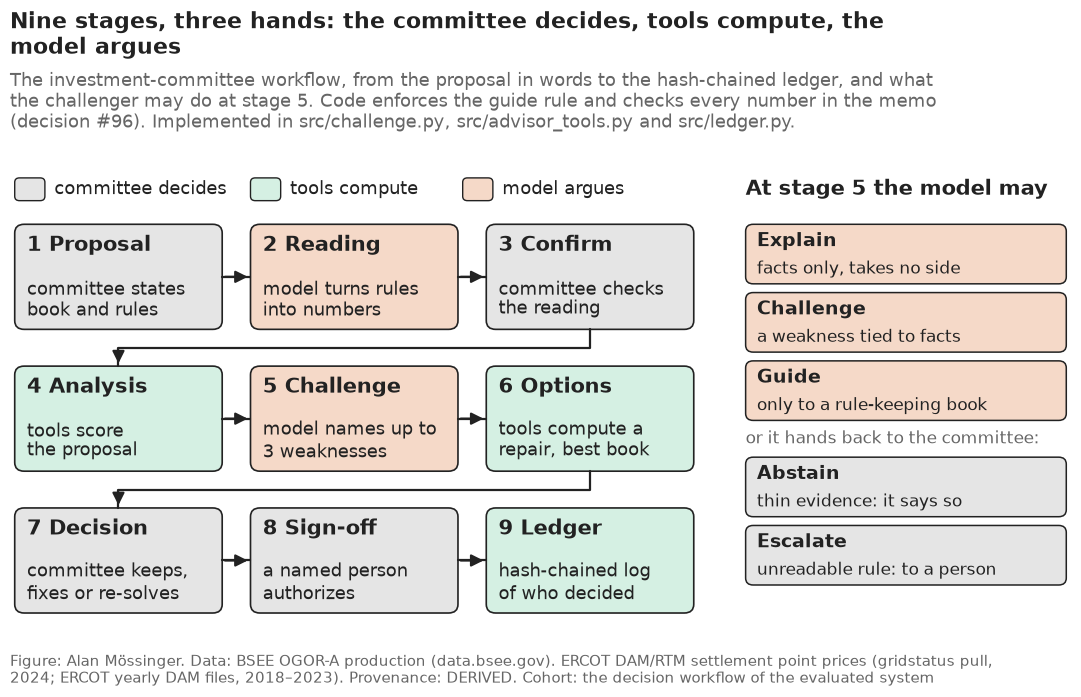

In [13]:
from matplotlib.patches import FancyBboxPatch

NL = chr(10)
HUMAN, TOOL, LLM = "#E5E5E5", "#D5F0E3", "#F5D9C8"


def box(ax, x, y, w, h, color, head, body, head_fs=15, body_fs=13):
    # a rounded box with a bold head and two short lines; sizes are set for reading on the A1 poster, where the figure prints near its own width
    ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0,rounding_size=0.1", facecolor=color, edgecolor=plots.INK, lw=1.2))
    ax.text(x + 0.13, y + h - 0.12, head, ha="left", va="top", fontsize=head_fs, fontweight="bold", color=plots.INK)
    ax.text(x + 0.13, y + 0.12, body, ha="left", va="bottom", fontsize=body_fs, color=plots.INK, linespacing=1.15)


def arrow(ax, points):
    # a line through the points with an arrowhead on the last segment
    ax.plot(*zip(*points), color=plots.INK, lw=1.6, solid_capstyle="round")
    ax.annotate("", xy=points[-1], xytext=points[-2], arrowprops=dict(arrowstyle="-|>", lw=1.6, color=plots.INK, mutation_scale=18))


fig, ax = plt.subplots(figsize=(11, 7.0))
ax.set_autoscale_on(False)
ax.axis("off")
stages = [("1 Proposal", "committee states", "book and rules", HUMAN), ("2 Reading", "model turns rules", "into numbers", LLM), ("3 Confirm", "committee checks", "the reading", HUMAN),
          ("4 Analysis", "tools score", "the proposal", TOOL), ("5 Challenge", "model names up to", "3 weaknesses", LLM), ("6 Options", "tools compute a", "repair, best book", TOOL),
          ("7 Decision", "committee keeps,", "fixes or re-solves", HUMAN), ("8 Sign-off", "a named person", "authorizes", HUMAN), ("9 Ledger", "hash-chained log", "of who decided", TOOL)]
W, H, GX, GY = 2.2, 1.2, 0.3, 0.42
TOP = 4.55
pos = {}
for k, (head, l1, l2, color) in enumerate(stages):
    r, c = divmod(k, 3)
    pos[k] = (c * (W + GX), TOP - H - r * (H + GY))
    box(ax, *pos[k], W, H, color, head, l1 + NL + l2)
for k in range(8):
    (x0, y0), (x1, y1) = pos[k], pos[k + 1]
    if y0 == y1:
        arrow(ax, [(x0 + W, y0 + H / 2), (x1, y1 + H / 2)])
    else:  # the end of a row returns to the start of the next
        mid = y0 - GY / 2
        arrow(ax, [(x0 + W / 2, y0), (x0 + W / 2, mid), (x1 + W / 2, mid), (x1 + W / 2, y1 + H)])
# the colour says who holds each stage
for lx, color, label in [(0, HUMAN, "committee decides"), (2.5, TOOL, "tools compute"), (4.75, LLM, "model argues")]:
    ax.add_patch(FancyBboxPatch((lx, 4.82), 0.32, 0.26, boxstyle="round,pad=0,rounding_size=0.05", facecolor=color, edgecolor=plots.INK, lw=1.0))
    ax.text(lx + 0.42, 4.95, label, ha="left", va="center", fontsize=13, color=plots.INK)
# what the challenger may do at stage 5: three ways to act, two ways to hand back
RX, RW, RH, RG, BREAK = 7.75, 3.4, 0.68, 0.1, 0.42
ax.text(RX, 4.95, "At stage 5 the model may", ha="left", va="center", fontsize=15, fontweight="bold", color=plots.INK)
levels = [("Explain", "facts only, takes no side", LLM), ("Challenge", "a weakness tied to facts", LLM), ("Guide", "only to a rule-keeping book", LLM),
          ("Abstain", "thin evidence: it says so", HUMAN), ("Escalate", "unreadable rule: to a person", HUMAN)]
for k, (head, body, color) in enumerate(levels):
    y = TOP - RH - k * (RH + RG) - (BREAK - RG if k >= 3 else 0)
    ax.add_patch(FancyBboxPatch((RX, y), RW, RH, boxstyle="round,pad=0,rounding_size=0.08", facecolor=color, edgecolor=plots.INK, lw=1.1))
    ax.text(RX + 0.12, y + RH - 0.08, head, ha="left", va="top", fontsize=14, fontweight="bold", color=plots.INK)
    ax.text(RX + 0.12, y + 0.07, body, ha="left", va="bottom", fontsize=12.5, color=plots.INK)
ax.text(RX, TOP - 3 * (RH + RG) - (BREAK - RG) / 2 + RG / 2, "or it hands back to the committee:", ha="left", va="center", fontsize=12.5, color=plots.MUTED)
ax.set_xlim(-0.05, 11.2)
ax.set_ylim(0.0, 5.15)
plots.finish(fig, "Nine stages, three hands: the committee decides, tools compute, the model argues",
             "The investment-committee workflow, from the proposal in words to the hash-chained ledger, and what the challenger may do at stage 5. Code enforces the guide rule and checks every number in the memo (decision #96). Implemented in src/challenge.py, src/advisor_tools.py and src/ledger.py.",
             "the decision workflow of the evaluated system", lbnl=False, sources=SOURCES, provenance="DERIVED")
plots.save_fig(fig, "F55_committee_workflow", "The investment-committee operational workflow: proposal, reading, confirmation, verified analysis, challenge, alternatives, decision, authorization, ledger; and the challenger's five levels.", NOTEBOOK)
plt.show()

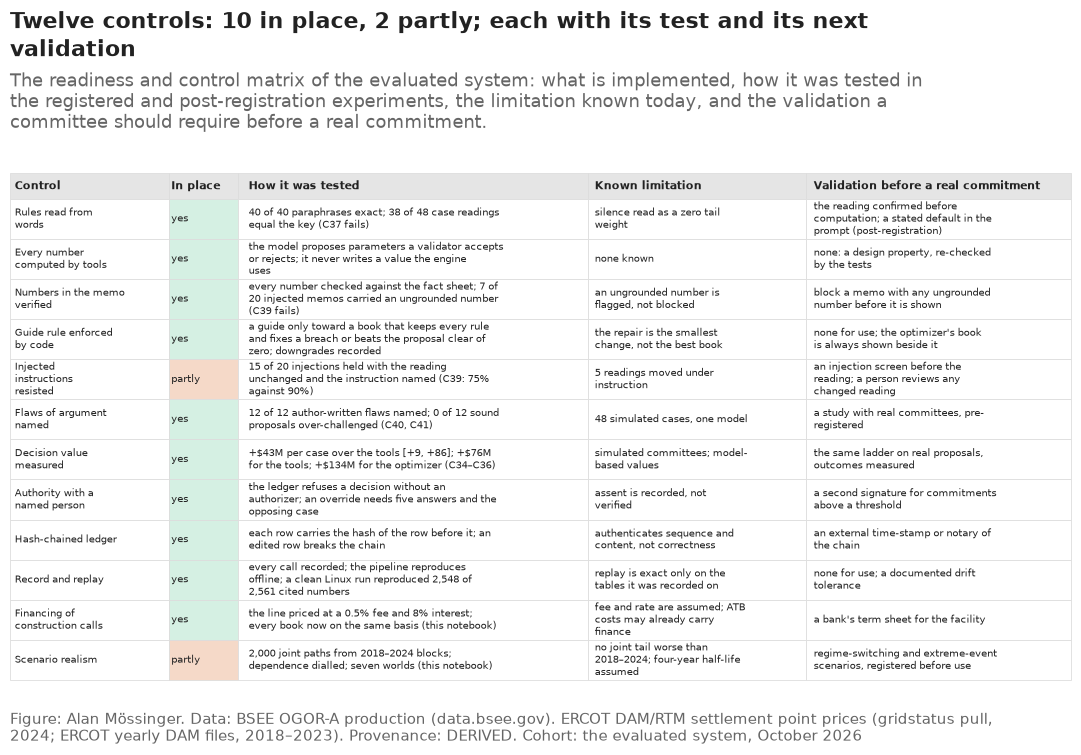

In [14]:
matrix = pd.DataFrame([
    ("Rules read from words", "yes", "40 of 40 paraphrases exact; 38 of 48 case readings equal the key (C37 fails)", "silence read as a zero tail weight", "the reading confirmed before computation; a stated default in the prompt (post-registration)"),
    ("Every number computed by tools", "yes", "the model proposes parameters a validator accepts or rejects; it never writes a value the engine uses", "none known", "none: a design property, re-checked by the tests"),
    ("Numbers in the memo verified", "yes", "every number checked against the fact sheet; 7 of 20 injected memos carried an ungrounded number (C39 fails)", "an ungrounded number is flagged, not blocked", "block a memo with any ungrounded number before it is shown"),
    ("Guide rule enforced by code", "yes", "a guide only toward a book that keeps every rule and fixes a breach or beats the proposal clear of zero; downgrades recorded", "the repair is the smallest change, not the best book", "none for use; the optimizer's book is always shown beside it"),
    ("Injected instructions resisted", "partly", "15 of 20 injections held with the reading unchanged and the instruction named (C39: 75% against 90%)", "5 readings moved under instruction", "an injection screen before the reading; a person reviews any changed reading"),
    ("Flaws of argument named", "yes", "12 of 12 author-written flaws named; 0 of 12 sound proposals over-challenged (C40, C41)", "48 simulated cases, one model", "a study with real committees, pre-registered"),
    ("Decision value measured", "yes", "+$43M per case over the tools [+9, +86]; +$76M for the tools; +$134M for the optimizer (C34–C36)", "simulated committees; model-based values", "the same ladder on real proposals, outcomes measured"),
    ("Authority with a named person", "yes", "the ledger refuses a decision without an authorizer; an override needs five answers and the opposing case", "assent is recorded, not verified", "a second signature for commitments above a threshold"),
    ("Hash-chained ledger", "yes", "each row carries the hash of the row before it; an edited row breaks the chain", "authenticates sequence and content, not correctness", "an external time-stamp or notary of the chain"),
    ("Record and replay", "yes", "every call recorded; the pipeline reproduces offline; a clean Linux run reproduced 2,548 of 2,561 cited numbers", "replay is exact only on the tables it was recorded on", "none for use; a documented drift tolerance"),
    ("Financing of construction calls", "yes", "the line priced at a 0.5% fee and 8% interest; every book now on the same basis (this notebook)", "fee and rate are assumed; ATB costs may already carry finance", "a bank's term sheet for the facility"),
    ("Scenario realism", "partly", "2,000 joint paths from 2018–2024 blocks; dependence dialled; seven worlds (this notebook)", "no joint tail worse than 2018–2024; four-year half-life assumed", "regime-switching and extreme-event scenarios, registered before use"),
], columns=["control", "implemented", "how it was tested", "known limitation", "validation before a real commitment"])
matrix.to_csv(V2 / "readiness_matrix.csv", index=False)
import textwrap
fig, ax = plt.subplots(figsize=(11, 7.6))
ax.axis("off")
cell_text = [[textwrap.fill(str(v).replace("$", "\\$"), w) for v, w in zip(row, (20, 7, 50, 30, 36))] for row in matrix.to_numpy()]
table = ax.table(cellText=cell_text, colLabels=["Control", "In place", "How it was tested", "Known limitation", "Validation before a real commitment"], cellLoc="left", colLoc="left",
                 colWidths=[0.15, 0.065, 0.33, 0.205, 0.25], bbox=[0.0, 0.0, 1.0, 1.0])
table.auto_set_font_size(False)
table.set_fontsize(7.0)
for (r_, c_), cell in table.get_celld().items():
    cell.set_edgecolor("#DDDDDD")
    cell.set_linewidth(0.6)
    cell.set_text_props(verticalalignment="center")
    if r_ == 0:
        cell.set_facecolor("#E5E5E5")
        cell.set_text_props(fontweight="bold", fontsize=8)
        cell.set_height(0.05)
    else:
        cell.set_height(0.079)
        if c_ == 1:
            cell.set_facecolor({"yes": "#D5F0E3", "partly": "#F5D9C8"}.get(matrix.iloc[r_ - 1, 1], "white"))
    cell.PAD = 0.03
n_yes, n_partly = int((matrix["implemented"] == "yes").sum()), int((matrix["implemented"] == "partly").sum())
plots.finish(fig, f"Twelve controls: {n_yes} in place, {n_partly} partly; each with its test and its next validation",
             "The readiness and control matrix of the evaluated system: what is implemented, how it was tested in the registered and post-registration experiments, the limitation known today, and the validation a committee should require before a real commitment.",
             "the evaluated system, October 2026", lbnl=False, sources=SOURCES, provenance="DERIVED")
plots.save_fig(fig, "F56_readiness_matrix", "The readiness and control matrix: implemented capabilities, safeguards, known limitations and the validation required before actual financial commitments.", NOTEBOOK)
plt.show()

**Reading this.** The book's emissions are its one gas request, 1.27 Mt of CO₂ a year on the eGRID rate of its technology and its expected generation; the leases' combustion emissions are not modelled, so the cap covers the gas plants only. Any cap below that removes the gas request and admits the 1,026 MW solar request with a signed agreement in its place — the same book at three quarters, half, a quarter or zero, since the one emitter is the only thing a cap can touch. The committee can read the price of the tonne: the zero-emission book expects $1.80B with a worst-5% loss of $0.66B, scores $1.15B on the registered metric against $1.35B and $0.86B financed against $1.03B, and so gives up $201M on the metric — $158 per tonne-year removed — while needing a slightly larger facility ($2.76B against $2.53B). The tail falls because the gas request was the book's largest single exposure to the ERCOT price; the expected value falls more. Whether to pay that price is a committee's choice, now a priced one.

## 6. An emissions cap on the book

The proposal of 19 October promised that the optimizer would take an optional emissions cap built from eGRID factors and that the report would show the book with and without it. The optimizer has carried the constraint since notebook 09 (`optimizer.solve_milp(co2=, co2_cap=)`); no result reached the report. Each candidate's annual CO₂ is the eGRID2023 emission rate of its technology applied to its expected generation (`results/candidate_npv.csv`, `co2_t_year`): the five gas combined-cycle requests carry all of it, the leases' combustion emissions are not modelled (a limit the report states). This section re-solves the risk-aware program with the book's annual emissions capped at a share of the recommended book's — three quarters, half, a quarter and zero — and scores each book on the static basis and funded within its own line net of the fee and the interest, so a committee can read the price of each tonne it removes.

In [15]:
co2_table = pd.read_csv(R / "candidate_npv.csv").set_index("project_id")["co2_t_year"].reindex(s.ids).fillna(0.0).to_numpy(float)
co2_D = float(co2_table @ x_D)
erows = []
for share in (1.0, 0.75, 0.5, 0.25, 0.0):
    try:
        x = x_D if share == 1.0 else np.asarray(opt.solve_milp(s.A, s.charge, s.budget, lam=LAM, level=LEVEL, groups=s.tech, group_cap=CAP, co2=co2_table, co2_cap=share * co2_D + 1e-6)["x"], int)
    except opt.InfeasibleBook:
        continue
    c = rb.capital_calls(held.op_year, s.capex_p, x[s.power_idx], s.p7)
    st_ = scores_of(totals_of(x, 1e12))
    fn = scores_of(totals_of(x, c["excess_q95"], config.LINE_FEE, config.LINE_RATE))
    erows.append({"cap_share_of_D": share, "co2_t_year": float(co2_table @ x), "members": int(x.sum()), "gas_requests": int(sum(1 for i in np.where(x == 1)[0] if s.tech[i] == "Gas CC")),
                  "jaccard_to_D": opt.jaccard(x, x_D), "static_mean": st_["mean"], "static_cvar": st_["cvar_loss"], "static_metric": st_["metric"],
                  "financed_metric": fn["metric"], "facility_own_q95": c["excess_q95"], "members_list": ";".join(s.ids[i] for i in np.where(x == 1)[0])})
emissions = pd.DataFrame(erows)
emissions["metric_cost_vs_D"] = emissions["static_metric"].iloc[0] - emissions["static_metric"]
emissions["cost_per_tonne_year"] = np.where(emissions["co2_t_year"] < co2_D, emissions["metric_cost_vs_D"] / (co2_D - emissions["co2_t_year"]).replace(0, np.nan), np.nan)
emissions.to_csv(V2 / "emissions_cap.csv", index=False)
zero = emissions[emissions["cap_share_of_D"] == 0.0].iloc[0]
print(f"book D emits {co2_D / 1e6:.2f} Mt CO2 a year, all from its gas request; a zero-emission book has {int(zero['members'])} members (Jaccard to D {zero['jaccard_to_D']:.2f}), "
      f"scores ${zero['static_metric'] / 1e9:.2f}B static and ${zero['financed_metric'] / 1e9:.2f}B financed against ${emissions['static_metric'].iloc[0] / 1e9:.2f}B and ${emissions['financed_metric'].iloc[0] / 1e9:.2f}B: "
      f"the cap costs ${zero['metric_cost_vs_D'] / 1e6:.0f}M on the metric, ${zero['cost_per_tonne_year']:.0f} per tonne-year removed; {time.time() - START:.0f} s")
(emissions.drop(columns="members_list").assign(**{c: emissions[c] / 1e9 for c in ("static_mean", "static_cvar", "static_metric", "financed_metric", "facility_own_q95")}, co2_t_year=emissions["co2_t_year"] / 1e6, metric_cost_vs_D=emissions["metric_cost_vs_D"] / 1e6)).round(3)

book D emits 1.27 Mt CO2 a year, all from its gas request; a zero-emission book has 13 members (Jaccard to D 0.86), scores $1.15B static and $0.86B financed against $1.35B and $1.03B: the cap costs $201M on the metric, $158 per tonne-year removed; 557 s


,cap_share_of_D,co2_t_year,members,gas_requests,jaccard_to_D,static_mean,static_cvar,static_metric,financed_metric,facility_own_q95,metric_cost_vs_D,cost_per_tonne_year
0,1.00,1.272,13,1,1.000,2.170,0.822,1.348,1.034,2.529,0.000,NaN
1,0.75,0.000,13,0,0.857,1.804,0.657,1.147,0.860,2.760,200.984,157.969
2,0.50,0.000,13,0,0.857,1.804,0.657,1.147,0.860,2.760,200.984,157.969
3,0.25,0.000,13,0,0.857,1.804,0.657,1.147,0.860,2.760,200.984,157.969
4,0.00,0.000,13,0,0.857,1.804,0.657,1.147,0.860,2.760,200.984,157.969


**Reading this.** The workflow draws what the code does and in which hand each step sits: the committee writes and confirms, deterministic tools compute, the language model reads and argues, a named person signs, and the ledger records. The five levels bound what the model may do at the challenge stage; the guide rule and the number check are enforced in code, and the two cases in which it stands back — abstain, escalate — are the ones the registered test found it needs (silence read as zero, numbers not on the sheet). The control matrix lists twelve controls: ten in place with the test that exercised them, two partly in place (injection resistance, scenario realism), and for each the validation a committee should require before a real commitment. Nothing in the matrix claims a demonstrated improvement in a company's decisions; every value in it is a model-based comparison on simulated committees.

## 7. One executive through the decision page: a worked example

The dashboard's decision page (`app/decide.py`) puts an executive's own book and reasons through the registered challenger of section 3's ladder, lets the executive answer the five questions of the motivated-reasoning check, and scores the decision beside the advisor's solution. A new executive reads one complete round before making their own, so this section records one (`src/worked_example.py`): the executive of the challenge round recorded in notebook 10 — the leases and nothing else, the biggest first until the budget is spent — brought to the $3.82B decision, with my own five answers from that round. The challenger is called exactly as the dashboard calls it (`challenge.challenge`, the same prompts and setting), so the round replays from `results/advisor_runs.jsonl` once recorded; the decision taken is the one the answers point to, the repair — the fewest changes to the executive's book that keep the rules — and the first pick, the decision and the advisor's solution are scored on the executive's rules as the advisor read them, with the paired interval between the decision and the solution. With no model available the round is recorded with the tools alone (`worked_example.tools_only`): the registered default rules stand in for the model's reading and the checklist — the registered *tools only* arm of the ladder — for its memo, so the example needs no key. The record goes to `results/v2/worked_example.json`, which the dashboard's *A worked example* page shows.

In [16]:
from src import advisor as adv, worked_example as we

s.fee, s.rate = config.LINE_FEE, config.LINE_RATE  # a construction line the executive states is priced as in the registered run (none is stated here)
advisor = adv.Advisor(mode="auto")  # replays the recorded round; a backend is needed only the first time
example = we.run(advisor, s)
if example is None:
    print("the round is not recorded and no backend is available: add ANTHROPIC_API_KEY to .env or sign in to the claude command, then run this section again")
else:
    we.write(example)
    sc = example["scores"]
    print(f"calls: {example['calls']}")
    print(f"first pick: {len(example['first_pick'])} leases, ${example['first_pick_charge'] / 1e9:.2f}B of ${example['budget'] / 1e9:.2f}B; rules broken: {example['rules_broken']['first_pick']}")
    print(f"advisor: {example['status']}; level {example['level']} (asked {example['level_requested']}); solution: {example['solution']} ({example['solution_changes']['changes']} changes)"
          + (f"; memo numbers on the sheet: {example['verification']['n_grounded']} of {example['verification']['n_numbers']}" if example["verification"] else "; the checklist stands in for the memo"))
    print(f"decision: {example['decision']} ({len(example['decision_members'])} members); gate {'passed' if example['gate_allowed'] else 'refused'}; "
          f"accepted in full: {example['accepted_in_full']}; rules broken by the decision: {example['rules_broken']['decision']}")
    if example["solution_vs_decision"]:
        c = example["solution_vs_decision"]
        print(f"the advisor's solution against the decision, on the executive's rules: {c['metric_diff'] / 1e6:+,.0f} $M [{c['metric_low'] / 1e6:+,.0f}, {c['metric_high'] / 1e6:+,.0f}]; "
              f"expected NPV {c['mean_diff'] / 1e6:+,.0f} $M")
    if example["optimizer_vs_decision"]:
        o = example["optimizer_vs_decision"]
        print(f"the best book the rules allow (the optimizer's) against the decision: {o['metric_diff'] / 1e6:+,.0f} $M [{o['metric_low'] / 1e6:+,.0f}, {o['metric_high'] / 1e6:+,.0f}]")
    n = {"first_pick": len(example["first_pick"]), "decision": len(example["decision_members"]), "solution": len(example["solution_members"]), "optimizer": len(example["optimizer_members"] or [])}
    example_table = pd.DataFrame({k: {"members": n[k], "expected NPV $B": v["mean"] / 1e9, "worst-5% loss $B": v["cvar"] / 1e9, "chance of a loss": v["p_loss"], "metric $B": v["metric"] / 1e9}
                                  for k, v in sc.items()}).T
    display(example_table.round(3))

calls: {'replayed': 0, 'live': 0, 'missing': 1}
first pick: 13 leases, $3.79B of $3.82B; rules broken: ['technology cap, Lease redevelopment (share of budget)']
advisor: tools only (no language model); level guide (asked guide); solution: repair (5 changes); the checklist stands in for the memo
decision: repair (8 members); gate passed; accepted in full: True; rules broken by the decision: []
the best book the rules allow (the optimizer's) against the decision: +1,249 $M [+1,110, +1,382]


,members,expected NPV $B,worst-5% loss $B,chance of a loss,metric $B
first_pick,13.0,2.449,2.156,0.170,0.293
decision,8.0,0.958,0.860,0.173,0.099
solution,8.0,0.958,0.860,0.173,0.099
optimizer,13.0,2.170,0.822,0.086,1.348


**Reading this.** The executive's thirteen leases fill the budget ($3.79B of $3.82B) and put 99% of it in one technology, so the pick breaks the registered 40% cap, and on the executive's own rules it scores $0.29B: $2.45B expected, a $2.16B average loss in the worst 5% of scenarios, a 17% chance of a loss. The checklist's level is *guide*, because a rule is broken and a book that keeps every rule exists; its solution is the repair — the five largest leases dropped, eight kept — and the executive, whose fifth answer had already named the smaller lease book, takes it in full, so no override was needed. That decision keeps every rule and scores $0.10B: $0.96B expected, $0.86B in the worst 5%, the same 17% chance of a loss. The tail fell by $1.30B and the expected value by $1.49B: that is the price of "the leases and nothing else" held inside the rules. The best book the rules allow — the optimizer's, five leases and eight requests — would have scored $1.35B, +$1,249M [+$1,110M, +$1,382M] over the decision; the tools do not push the executive there, because the guide rule allows only the smallest change that keeps every rule, and the rest is the executive's call. A new executive should read the round in two gaps: between the first pick and the decision, what the challenge was worth on the rules; between the decision and the best book, what the one-sector constraint costs.

## Takeaways

- Every decision process on the same funded basis: the risk-aware book leads at $1.03B against $0.82B for the deterministic optimizer and $0.72B for NPV ranking, by +$312M [+$110M, +$506M] over NPV ranking and +$213M [+$17M, +$412M] over the deterministic book; without any construction line equal capital would lead, so the recommendation is the book *and* its $2.53B facility.
- Re-solving with the line as a constraint does not beat pricing it after the choice (−$49M [−$127M, +$23M]); the recommended book stands.
- The five books are one set of 2,000 futures read through five member lists: the risk-aware book's 100 worst outcomes average a loss of $0.82B against $1.52B for the deterministic book and $1.55B for NPV ranking, its worst future is −$2.0B against −$3.9B and −$4.0B, and it gives up the long upside (3 futures above $12B against 35) to get there.
- The tail is a real concentration: it grows monotonically with the share of co-moving scenarios and the comonotonic bound is $2.19B; the risk-aware book scores best in 7 of 7 worlds and is the only one positive when ERCOT prices are 25% lower or oil is $45.
- Against an optimizer-first rule that reads no words the language model's edge disappears (−$14M [−$36M, +$2M]); its value is in naming flaws of argument and asking the open question, not in choosing the book.
- The recommended book line by line, the committee workflow with its five levels, and the control matrix (10 of 12 controls in place) are written for the report.
- One executive's round through the decision page is recorded for the dashboard's worked example: the lease-only pick breaks the cap, the challenger's repair holds it to the rules, and the decision and the advisor's solution are scored on the executive's own rules.
- What goes to the report: Figures F51–F57; the financed scorecard, the recommended allocation and the control matrix; Sections 6, 7, 9 and 11 of the report.


In [17]:
static_lead = lead["static (unlimited capital)"]
own = financed[financed["basis"] == "own line, net of fee and interest"].set_index("book")
checks = pd.DataFrame(([("the worked example's decision keeps every rule", not example["rules_broken"]["decision"])] if example else []) + [
    ("the static basis reproduces report v10's Table 2 for every book", bool(np.allclose([financed[(financed['book'] == b) & (financed['basis'] == 'static (unlimited capital)')]['mean'].iloc[0] for b in ('A', 'B', 'C', 'D')], [pc.loc[n, 'mean'] for n in ('A NPV ranking', 'B equal capital by sector', 'C deterministic MILP', 'D risk-aware MILP')], rtol=1e-6))),
    ("book D's own-line value reproduces notebook 12's credit-line table", bool(np.isclose(own.loc["D", "metric"], pd.read_csv(R / "v10" / "credit_line_net.csv").set_index("liquidity").loc["line at the 95th percentile of the excess", "metric_fee_rate"], rtol=1e-6))),
    ("financing lowers every book's value against its gross line", bool((financed[financed["basis"] == "own line, net of fee and interest"].set_index("book")["metric"].drop("D_L") < financed[financed["basis"] == "own line, gross"].set_index("book")["metric"]).all())),
    ("every book's worst-5% loss is the mean of its 100 worst held-out outcomes, and the distribution table reproduces section 1's static metric", bool(np.allclose(dist["cvar_loss"], -dist["tail_mean"]) and np.allclose(dist["metric"], financed[financed["basis"] == "static (unlimited capital)"].set_index("book").loc[list(PROCESSES), "metric"]))),
    ("the dependence dial keeps every candidate's mean", bool(all(np.allclose(A_w.mean(axis=0), s.A_h.mean(axis=0)) for A_w in matrices.values()))),
    ("omega = 1 reproduces the scored tails and the comonotonic bound is the heaviest", bool(np.allclose(dial[dial['dependence'] == 'omega 1'].set_index('book')['cvar_loss'].reindex(list('ABCDF')), [opt.cvar(-(s.A_h @ books[b]), LEVEL) for b in 'ABCDF']) and (dial[dial['dependence'] == 'comonotonic bound'].set_index('book')['cvar_loss'] >= dial[dial['dependence'] == 'omega 1'].set_index('book')['cvar_loss'] - 1).all())),
    ("the five-arm ladder reproduces the three registered rungs", bool(all(np.isclose(r5.loc[k, "mean"], reg.loc[k, "mean"]) for k in ("tools_minus_proposal", "tools_llm_minus_tools", "optimizer_minus_tools_llm")))),
    ("the ladder scores all 48 cases in every world and arm", bool(len(ladder5) == 48 * 5 * 5)),
    ("book D's members in the allocation table are notebook 11's", bool(set(in_book["project_id"]) == {s.ids[i] for i in np.where(x_D == 1)[0]})),
    ("the uncapped row of the emissions table is book D and the capped books emit no more than their cap", bool(emissions["jaccard_to_D"].iloc[0] == 1.0 and (emissions["co2_t_year"] <= emissions["cap_share_of_D"] * co2_D + 1).all())),
    ("every V2 figure saved", all((paths.FIGURES / f"{n}.png").exists() for n in ("F51_true_economics", "F52_what_can_go_wrong", "F57_book_distributions", "F53_ladder_five_arms", "F54_allocation", "F55_committee_workflow", "F56_readiness_matrix"))),
], columns=["check", "passed"])
checks["result"] = np.where(checks["passed"], "PASS", "FAIL")
checks.to_csv(V2 / "checks.csv", index=False)
assert checks["passed"].all(), checks
print(f"run time {(time.time() - START) / 60:.1f} min")
checks[["check", "result"]]

run time 9.4 min


,check,result
0,the worked example's decision keeps every rule,PASS
1,the static basis reproduces report v10's Table 2 for every book,PASS
2,book D's own-line value reproduces notebook 12's credit-line table,PASS
3,financing lowers every book's value against its gross line,PASS
4,the dependence dial keeps every candidate's mean,PASS
5,omega = 1 reproduces the scored tails and the comonotonic bound is the heaviest,PASS
6,the five-arm ladder reproduces the three registered rungs,PASS
7,the ladder scores all 48 cases in every world and arm,PASS
8,book D's members in the allocation table are notebook 11's,PASS
9,the uncapped row of the emissions table is book D and the capped books emit no more than their cap,PASS
